<a href="https://colab.research.google.com/github/syedh99/SMS_Spam_Proj/blob/main/SMS_Spam_Checker.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# SMS Spam Detection: Prompting, Label Scoring, and Robustness

**CSI-4130/5130 — Artificial Intelligence Semester Project**

## Project Overview

This project evaluates several methods for identifying spam SMS messages.

We compare traditional machine learning against Google's FLAN-T5 language model and investigate how prompt engineering, classification methods, and text obfuscation affect performance.

### Experiments

| Experiment | Description |
|---|---|
| E01 | Original TF-IDF baseline and FLAN-T5 prompting |
| E02 | Improved zero-shot and few-shot prompting |
| E03 | Candidate-label scoring and character-level TF-IDF |
| E04 | Modern SMS evaluation, including political outreach |
| E05 | Final evaluation on previously unseen messages |

### Research Questions

1. How does traditional machine learning compare with an instruction-tuned language model?
2. Does improving the prompt improve spam classification?
3. Does candidate-label scoring outperform text generation?
4. How does character-level TF-IDF handle disguised spam keywords?
5. Do the experimental improvements generalize to unseen messages?

### Technologies

- Python and Google Colab
- PyTorch
- Hugging Face Transformers
- Google FLAN-T5-base
- Scikit-learn
- UCI SMS Spam Collection

**Note:** The project uses pretrained language models without fine-tuning.

All experiments are saved into a single results package at the end.

## 0. How to Run This Notebook

1. Open Google Colab.
2. Select Runtime → Change runtime type → T4 GPU.
3. Run the cells sequentially, starting at the top.
4. The UCI SMS dataset and FLAN-T5 model will download automatically.
5. All experiments will save their results to a common folder.
6. The final export cell generates and downloads one ZIP file.

### Evaluation Strategy

- Development sample: 240 messages for E01–E03.
- Final evaluation: 300 different messages for E05.
- E04: 12 synthetic modern SMS examples for qualitative analysis.

The final E05 messages are not used to modify or select prompts.

Keep the final test set independent to avoid overfitting the evaluation.

## 1. Environment and Configuration

This notebook is designed for Google Colab with an NVIDIA Tesla T4 GPU.

Required libraries:

- PyTorch
- Transformers
- SentencePiece
- Scikit-learn
- Pandas
- NumPy
- Matplotlib

A fixed random seed is used to make the experiments reproducible.

In [ ]:
%pip -q install "sentencepiece>=0.2.0" "scikit-learn>=1.6" "safetensors>=0.4"

In [ ]:
import io
import json
import random
import re
import shutil
import sys
import time
import urllib.request
import zipfile

from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

from IPython.display import display

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    precision_recall_fscore_support
)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline

from transformers import AutoModelForSeq2SeqLM, AutoTokenizer


# ==================================================
# PROJECT CONFIGURATION
# ==================================================

SEED = 42

MODEL_NAME = "google/flan-t5-base"

# Original development evaluation size
DEV_SAMPLES = 240

# E05: final unseen messages
# Change to None to use all remaining 1,050 messages
FINAL_SAMPLES = 300

BATCH_SIZE = 12

MAX_INPUT_TOKENS = 384
MAX_OUTPUT_TOKENS = 8


# ==================================================
# OUTPUT DIRECTORY
# ==================================================

OUTPUT_DIR = Path("sms_spam_project_results")

# Start each full run with a clean output folder
if OUTPUT_DIR.exists():
    shutil.rmtree(OUTPUT_DIR)

OUTPUT_DIR.mkdir(parents=True)


# ==================================================
# REPRODUCIBILITY
# ==================================================

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)


# ==================================================
# GPU CONFIGURATION
# ==================================================

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Python:", sys.version.split()[0])
print("PyTorch:", torch.__version__)
print("Device:", DEVICE)

if DEVICE.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("WARNING: GPU not enabled. LLM inference will be slower.")

print("Development samples:", DEV_SAMPLES)
print("Final evaluation samples:", FINAL_SAMPLES or "all remaining")

PyTorch version: 2.11.0+cpu
Model: google/flan-t5-base
Device: cpu
Evaluation messages: 240


## 2. Dataset Preparation

We use the UCI SMS Spam Collection dataset.

Source:
https://archive.ics.uci.edu/dataset/228/sms+spam+collection

### Labels

- ham: Legitimate SMS messages
- spam: Unwanted or fraudulent SMS messages

### Preprocessing

1. Download the dataset.
2. Remove duplicate SMS text.
3. Perform a stratified 75% training / 25% holdout split.
4. Select 240 development messages.
5. Reserve the remaining holdout messages for independent final evaluation.

The same development messages are used across E01–E03.

E05 uses a separate subset that does not overlap with training or development.

In [ ]:
DATA_URLS = [
    "https://archive.ics.uci.edu/static/public/228/sms+spam+collection.zip",
    "https://archive.ics.uci.edu/ml/machine-learning-databases/00228/smsspamcollection.zip",
]


def fetch_sms_collection():

    last_error = None

    for url in DATA_URLS:

        try:
            with urllib.request.urlopen(
                url, timeout=40
            ) as response:
                data = response.read()

            with zipfile.ZipFile(io.BytesIO(data)) as zf:

                matches = [
                    p for p in zf.namelist()
                    if p.split("/")[-1] == "SMSSpamCollection"
                ]

                if not matches:
                    raise ValueError("Dataset file missing")

                content = zf.read(
                    matches[0]
                ).decode("latin-1")

            rows = []

            for line in content.splitlines():

                label, tab, message = line.partition("\t")

                if (
                    tab
                    and label in ("ham", "spam")
                    and message.strip()
                ):
                    rows.append((label, message.strip()))

            if len(rows) < 5000:
                raise ValueError("Unexpected dataset size")

            print("Downloaded:", url)

            return pd.DataFrame(
                rows,
                columns=["label", "text"]
            )

        except Exception as exc:
            print("Download source failed:", exc)
            last_error = exc

    raise RuntimeError(
        "Unable to download SMS dataset"
    ) from last_error


# ==================================================
# LOAD AND CLEAN DATA
# ==================================================

raw_df = fetch_sms_collection()

data_df = raw_df.drop_duplicates(
    subset="text"
).reset_index(drop=True)


# ==================================================
# TRAIN / TEST SPLIT
# ==================================================

train_df, test_df = train_test_split(
    data_df,
    test_size=0.25,
    random_state=SEED,
    stratify=data_df["label"]
)

train_df = train_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)


# ==================================================
# DEVELOPMENT / FINAL HOLDOUT SPLIT
# ==================================================

assert 0 < DEV_SAMPLES < len(test_df)

dev_df, e05_pool = train_test_split(
    test_df,
    train_size=DEV_SAMPLES,
    random_state=SEED,
    stratify=test_df["label"]
)

dev_df = dev_df.reset_index(drop=True)
e05_pool = e05_pool.reset_index(drop=True)


# E05 independent evaluation sample
if FINAL_SAMPLES is None:

    final_df = e05_pool.copy()

else:

    assert 0 < FINAL_SAMPLES <= len(e05_pool)

    if FINAL_SAMPLES == len(e05_pool):

        final_df = e05_pool.copy()

    else:

        final_df, _ = train_test_split(
            e05_pool,
            train_size=FINAL_SAMPLES,
            random_state=SEED + 1,
            stratify=e05_pool["label"]
        )

final_df = final_df.reset_index(drop=True)


# ==================================================
# VERIFY NO DATA OVERLAP
# ==================================================

assert set(train_df.text).isdisjoint(set(dev_df.text))
assert set(train_df.text).isdisjoint(set(final_df.text))
assert set(dev_df.text).isdisjoint(set(final_df.text))


print("\nDATASET SUMMARY")

print("Original records:", len(raw_df))
print("Unique records:", len(data_df))

print("Training:", len(train_df))
print("Full holdout:", len(test_df))

print("Development:", len(dev_df))
print("Remaining E05 pool:", len(e05_pool))
print("Final evaluation:", len(final_df))

print("\nDevelopment class distribution:")
display(dev_df["label"].value_counts())

print("\nSample messages:")
display(train_df.head())

Original records: 5574
Unique records: 5160


,count
label,
ham,4518
spam,642


,label,text
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


## 3. SMS Keyword Obfuscation

Spam messages frequently disguise keywords to avoid detection.

Examples:

- free → fr33
- win → w1n
- prize → pr1ze
- claim → cl@im
- urgent → urg3nt

We apply deterministic character substitutions to messages.

Each classifier is evaluated on:

1. Original SMS messages
2. Obfuscated SMS messages

We also analyze only the messages that were actually modified.

In [ ]:
OBFUSCATIONS = {
    "free": "fr33",
    "win": "w1n",
    "winner": "w1nn3r",
    "prize": "pr1ze",
    "urgent": "urg3nt",
    "claim": "cl@im",
    "cash": "ca$h",
    "call": "c@ll",
    "reply": "r3ply",
    "offer": "0ffer",
    "bonus": "b0nus",
    "credit": "cr3dit"
}


OBFUSCATION_RE = re.compile(
    r"\b(?:"
    + "|".join(
        map(
            re.escape,
            sorted(OBFUSCATIONS, key=len, reverse=True)
        )
    )
    + r")\b",
    flags=re.IGNORECASE
)


def obfuscate(text):

    return OBFUSCATION_RE.sub(
        lambda match: OBFUSCATIONS[
            match.group(0).lower()
        ],
        text
    )


def attach_obfuscation(frame):

    result = frame.copy().reset_index(drop=True)

    result["obfuscated_text"] = (
        result["text"].map(obfuscate)
    )

    result["was_changed"] = (
        result["obfuscated_text"] != result["text"]
    )

    return result


# Apply transformations
dev_df = attach_obfuscation(dev_df)
final_df = attach_obfuscation(final_df)


print(
    "Development messages modified:",
    int(dev_df.was_changed.sum())
)

print(
    "Final evaluation messages modified:",
    int(final_df.was_changed.sum())
)


display(
    dev_df.loc[
        dev_df["was_changed"],
        ["label", "text", "obfuscated_text"]
    ].head()
)

Training samples: 3870
Testing samples: 1290
Evaluation samples: 240

Evaluation class distribution:


,count
label,
ham,210
spam,30


## 4. Traditional Machine Learning Baselines

We compare two representations of SMS text.

### Word-Level TF-IDF

Transforms words and word pairs into numerical features.

This is the original E01 baseline.

### Character-Level TF-IDF

Transforms character sequences into numerical features.

This is the E03 improvement, designed to capture patterns
that may remain useful when words contain misspellings
or character substitutions.

Both representations use Logistic Regression.

Both models are trained only on the training dataset.

In [ ]:
# ==================================================
# WORD-LEVEL TF-IDF
# ==================================================

word_model = Pipeline([
    (
        "tfidf",
        TfidfVectorizer(
            ngram_range=(1, 2),
            min_df=2,
            sublinear_tf=True
        )
    ),
    (
        "classifier",
        LogisticRegression(
            max_iter=1500,
            class_weight="balanced",
            random_state=SEED
        )
    )
])


# ==================================================
# CHARACTER-LEVEL TF-IDF
# ==================================================

char_model = Pipeline([
    (
        "tfidf",
        TfidfVectorizer(
            analyzer="char",
            ngram_range=(3, 5),
            min_df=2,
            max_features=60000,
            sublinear_tf=True
        )
    ),
    (
        "classifier",
        LogisticRegression(
            max_iter=1500,
            class_weight="balanced",
            random_state=SEED
        )
    )
])


# ==================================================
# TRAIN MODELS
# ==================================================

word_model.fit(
    train_df["text"],
    train_df["label"]
)

char_model.fit(
    train_df["text"],
    train_df["label"]
)


print("Both traditional ML models trained successfully.")

Baseline classifier trained successfully!
Message: Congratulations! You won a free prize!
Prediction: spam


## 5. FLAN-T5 and Prompt Engineering

We use Google FLAN-T5-base, an instruction-tuned
encoder-decoder language model.

We preserve both prompting configurations separately:

### E01: Original Prompts
- Original spam/ham instructions
- Few-shot examples sampled from training data

### E02: Improved Prompts
- More explicit spam/ham definitions
- Four handcrafted few-shot examples

Both experiments use the same pretrained model.

No model weights are fine-tuned.

Note: E02 changes both instructions and example selection.

In [ ]:
# ==================================================
# LOAD FLAN-T5
# ==================================================

tokenizer = AutoTokenizer.from_pretrained(
    MODEL_NAME
)

model = AutoModelForSeq2SeqLM.from_pretrained(
    MODEL_NAME,
    use_safetensors=True
)

model = model.to(DEVICE).eval()

print("Loaded:", MODEL_NAME)


# ==================================================
# E01 - ORIGINAL PROMPT CONFIGURATION
# ==================================================

E01_EXAMPLE_ROWS = []

for label in ("ham", "spam"):

    eligible = train_df[
        (train_df.label == label)
        & train_df.text.str.len().between(15, 110)
    ]

    selected = eligible.sample(
        n=2,
        random_state=SEED
    )

    for text in selected.text:

        E01_EXAMPLE_ROWS.append((
            re.sub(r"\s+", " ", text).strip(),
            label
        ))


E01_EXAMPLE_BLOCK = "\n\n".join(
    f"SMS: {text}\nLabel: {label}"
    for text, label in E01_EXAMPLE_ROWS
)


E01_INSTRUCTIONS = (
    "Classify the SMS message as spam or ham. "
    "Spam means an unsolicited commercial message, "
    "a scam, or a deceptive prize or cash offer. "
    "Ham means a legitimate ordinary message. "
    "Respond with exactly one lowercase word: "
    "spam or ham."
)


def build_prompt_e01(message, strategy):

    if strategy == "Zero-shot":

        return (
            f"{E01_INSTRUCTIONS}\n\n"
            f"SMS: {message}\n"
            "Label:"
        )

    if strategy == "Few-shot":

        return (
            f"{E01_INSTRUCTIONS}\n\n"
            f"Examples:\n"
            f"{E01_EXAMPLE_BLOCK}\n\n"
            f"SMS: {message}\n"
            "Label:"
        )

    raise ValueError(strategy)


# ==================================================
# E02 - IMPROVED PROMPT CONFIGURATION
# ==================================================

E02_INSTRUCTIONS = (
    "You are classifying SMS text messages.\n"
    "Spam: Unwanted advertisements, scams, fake prizes, "
    "and unsolicited promotional messages.\n"
    "Ham: Normal personal messages, conversations, "
    "appointments, and routine communication.\n"
    "Respond with only one word: ham or spam."
)


E02_EXAMPLES = [
    ("Are we still meeting for dinner tonight?", "ham"),
    ("Hey, I'll call you when I get home.", "ham"),
    ("WIN a FREE CASH PRIZE! Claim it now!", "spam"),
    ("Congratulations! Click here to collect your reward.", "spam")
]


def build_prompt_e02(message, strategy):

    prompt = E02_INSTRUCTIONS + "\n\n"

    if strategy == "Few-shot":

        for text, label in E02_EXAMPLES:

            prompt += (
                f"SMS: {text}\n"
                f"Label: {label}\n\n"
            )

    elif strategy != "Zero-shot":
        raise ValueError(strategy)

    return prompt + f"SMS: {message}\nLabel:"


# ==================================================
# VALIDATION
# ==================================================

assert "Examples:" in build_prompt_e01(
    "hello", "Few-shot"
)

assert "WIN a FREE CASH PRIZE" in build_prompt_e02(
    "hello", "Few-shot"
)

assert "WIN a FREE CASH PRIZE" not in build_prompt_e02(
    "hello", "Zero-shot"
)

print("E01 and E02 prompting configurations ready.")

Messages modified: 48
Total evaluation messages: 240

Modified messages by class:


,was_changed
label,
ham,23
spam,25


,label,text,obfuscated_text
13,ham,This is wishing you a great day. Moji told me ...,This is wishing you a great day. Moji told me ...
18,spam,74355 XMAS iscoming & ur awarded either Â£500 ...,74355 XMAS iscoming & ur awarded either Â£500 ...
20,spam,FREE GAME. Get Rayman Golf 4 FREE from the O2 ...,fr33 GAME. Get Rayman Golf 4 fr33 from the O2 ...
21,spam,We tried to contact you re our offer of New Vi...,We tried to contact you re our 0ffer of New Vi...
28,ham,"Sorry, in meeting I'll call you later","Sorry, in meeting I'll c@ll you later"


## 6. Shared Classification and Evaluation Framework

To simplify the notebook, every model uses the same
prediction and evaluation framework.

### Classification Methods

1. Traditional Logistic Regression
2. FLAN-T5 text generation
3. FLAN-T5 candidate-label scoring

### Evaluation Metrics

- Accuracy
- Spam precision
- Spam recall
- Spam F1-score
- Inference time
- Invalid output count

### Inference Optimization

The models first classify the original messages.

For obfuscated evaluation, only messages that were
actually modified require additional inference.

Unmodified messages reuse their original predictions.

Therefore, obfuscated inference times represent
incremental processing time, not full-dataset runtime.

In [ ]:
# ==================================================
# OUTPUT PARSING
# ==================================================

def parse_label(text):

    normalized = re.sub(
        r"[^a-z]",
        "",
        str(text).lower().strip()
    )

    if normalized in {"ham", "spam"}:
        return normalized

    return "invalid"


# ==================================================
# FLAN-T5 TEXT GENERATION
# ==================================================

@torch.inference_mode()
def predict_generated(messages, prompt_fn, strategy):

    messages = list(messages)

    raw_outputs = []
    start = time.perf_counter()

    for pos in range(0, len(messages), BATCH_SIZE):

        batch = messages[pos:pos + BATCH_SIZE]

        prompts = [
            prompt_fn(str(m), strategy)
            for m in batch
        ]

        inputs = tokenizer(
            prompts,
            return_tensors="pt",
            padding=True,
            truncation=True,
            max_length=MAX_INPUT_TOKENS
        ).to(DEVICE)

        generated = model.generate(
            **inputs,
            do_sample=False,
            max_new_tokens=MAX_OUTPUT_TOKENS
        )

        decoded = tokenizer.batch_decode(
            generated,
            skip_special_tokens=True
        )

        raw_outputs.extend(decoded)

    predictions = [
        parse_label(x)
        for x in raw_outputs
    ]

    elapsed = time.perf_counter() - start

    return predictions, raw_outputs, elapsed


# ==================================================
# FLAN-T5 CANDIDATE-LABEL SCORING
# ==================================================

@torch.inference_mode()
def predict_label_scoring(messages):

    messages = list(messages)

    options = ["ham", "spam"]

    option_ids = tokenizer(
        options,
        padding=True,
        return_tensors="pt"
    )["input_ids"].to(DEVICE)

    predictions = []

    start = time.perf_counter()

    for pos in range(0, len(messages), BATCH_SIZE):

        batch = messages[pos:pos + BATCH_SIZE]

        prompts = [
            build_prompt_e02(str(m), "Zero-shot")
            for m in batch
        ]

        inputs = tokenizer(
            prompts,
            padding=True,
            truncation=True,
            max_length=MAX_INPUT_TOKENS,
            return_tensors="pt"
        ).to(DEVICE)

        # Repeat each SMS for both candidate labels
        paired_ids = inputs["input_ids"].repeat_interleave(
            2,
            dim=0
        )

        paired_mask = inputs["attention_mask"].repeat_interleave(
            2,
            dim=0
        )

        labels = option_ids.repeat(
            len(batch),
            1
        )

        labels[labels == tokenizer.pad_token_id] = -100

        # Score each candidate output
        result = model(
            input_ids=paired_ids,
            attention_mask=paired_mask,
            labels=labels
        )

        log_probs = torch.log_softmax(
            result.logits.float(),
            dim=-1
        )

        valid = labels.ne(-100)

        token_scores = log_probs.gather(
            -1,
            labels.clamp_min(0).unsqueeze(-1)
        ).squeeze(-1)

        scores = token_scores.masked_fill(
            ~valid,
            0
        ).sum(dim=1).reshape(len(batch), 2)

        best_indices = scores.argmax(
            dim=1
        ).tolist()

        predictions.extend(
            options[int(i)]
            for i in best_indices
        )

    elapsed = time.perf_counter() - start

    return (
        predictions,
        [""] * len(predictions),
        elapsed
    )


# ==================================================
# TRADITIONAL MACHINE LEARNING
# ==================================================

def predict_classical(messages, classifier):

    start = time.perf_counter()

    predictions = classifier.predict(
        list(messages)
    ).tolist()

    elapsed = time.perf_counter() - start

    return (
        predictions,
        [""] * len(predictions),
        elapsed
    )


# ==================================================
# ORIGINAL / OBFUSCATED PREDICTIONS
# ==================================================

def paired_predict(frame, predict_fn):

    original, original_raw, original_seconds = (
        predict_fn(frame.text.tolist())
    )

    modified = list(original)
    modified_raw = list(original_raw)

    changed_positions = np.flatnonzero(
        frame.was_changed.to_numpy()
    )

    incremental_seconds = 0.0

    if len(changed_positions):

        changed_texts = frame.iloc[
            changed_positions
        ].obfuscated_text.tolist()

        changed_pred, changed_raw, incremental_seconds = (
            predict_fn(changed_texts)
        )

        for index, prediction, raw in zip(
            changed_positions,
            changed_pred,
            changed_raw
        ):

            modified[index] = prediction
            modified_raw[index] = raw

    return {
        "Original": (
            original,
            original_raw,
            original_seconds
        ),
        "Obfuscated": (
            modified,
            modified_raw,
            incremental_seconds
        )
    }


# ==================================================
# METRIC CALCULATION
# ==================================================

def metric_row(
    y_true,
    y_pred,
    method,
    scenario,
    experiment,
    seconds,
    changed_count
):

    precision, recall, f1, _ = (
        precision_recall_fscore_support(
            y_true,
            y_pred,
            labels=["spam"],
            zero_division=0
        )
    )

    return {
        "experiment": experiment,
        "method": method,
        "scenario": scenario,
        "n": len(y_true),
        "changed_in_full_set": changed_count,
        "accuracy": accuracy_score(y_true, y_pred),
        "spam_precision": float(precision[0]),
        "spam_recall": float(recall[0]),
        "spam_f1": float(f1[0]),
        "invalid_outputs": sum(
            p == "invalid"
            for p in y_pred
        ),
        "inference_seconds": round(float(seconds), 3)
    }


# ==================================================
# EVALUATE MULTIPLE MODELS
# ==================================================

def evaluate_methods(frame, method_specs):

    full_rows = []
    changed_rows = []

    details = frame[
        [
            "label",
            "text",
            "obfuscated_text",
            "was_changed"
        ]
    ].copy()

    changed_idx = np.flatnonzero(
        frame.was_changed.to_numpy()
    )

    truth = frame.label.tolist()

    for experiment, method, fn in method_specs:

        print("Evaluating:", method)

        outputs = paired_predict(frame, fn)

        for scenario, (pred, raw, seconds) in outputs.items():

            # Full sample metrics
            full_rows.append(
                metric_row(
                    truth,
                    pred,
                    method,
                    scenario,
                    experiment,
                    seconds,
                    len(changed_idx)
                )
            )

            # Changed-only metrics
            if len(changed_idx):

                changed_rows.append(
                    metric_row(
                        [truth[i] for i in changed_idx],
                        [pred[i] for i in changed_idx],
                        method,
                        scenario,
                        experiment,
                        seconds,
                        len(changed_idx)
                    )
                )

            # Individual predictions
            safe = re.sub(
                r"[^a-zA-Z0-9]+",
                "_",
                method
            ).strip("_")

            details[f"{safe}_{scenario}"] = pred

            # Preserve original text-generation outputs
            if (
                method.startswith("E01 ")
                or method.startswith("E02 ")
            ):

                details[f"raw_{safe}_{scenario}"] = raw

    return (
        pd.DataFrame(full_rows),
        pd.DataFrame(changed_rows),
        details
    )


# ==================================================
# SAVE EXPERIMENT RESULTS
# ==================================================

def save_experiment(
    tag,
    metrics,
    changed,
    predictions
):

    metrics.to_csv(
        OUTPUT_DIR / f"{tag}_metrics.csv",
        index=False
    )

    changed.to_csv(
        OUTPUT_DIR / f"{tag}_changed_only_metrics.csv",
        index=False
    )

    predictions.to_csv(
        OUTPUT_DIR / f"{tag}_predictions.csv",
        index=False
    )


print("Shared evaluation functions initialized.")

Loading language model: google/flan-t5-base


Loading weights:   0%|          | 0/282 [00:00<?, ?it/s]

[transformers] The tied weights mapping and config for this model specifies to tie shared.weight to lm_head.weight, but both are present in the checkpoints with different values, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning.


Model loaded successfully!
Device: cpu
Load time: 6.48 seconds


## 7. E01 — Original Model Comparison

This experiment reproduces our initial methodology.

Models evaluated:

1. Word-level TF-IDF + Logistic Regression
2. FLAN-T5 Zero-shot with original instructions
3. FLAN-T5 Few-shot with examples sampled from training data

All models use the same 240 development messages.

### Previous Finding

The initial language model frequently predicted spam
for legitimate messages.

Traditional Logistic Regression achieved substantially
better spam classification performance.

We reproduce E01 separately so later prompt changes
do not overwrite its original methodology.

In [ ]:
E01_METHODS = [
    (
        "E01",
        "Word TF-IDF + LR",
        lambda msgs: predict_classical(
            msgs, word_model
        )
    ),
    (
        "E01",
        "E01 Zero-shot",
        lambda msgs: predict_generated(
            msgs, build_prompt_e01, "Zero-shot"
        )
    ),
    (
        "E01",
        "E01 Few-shot",
        lambda msgs: predict_generated(
            msgs, build_prompt_e01, "Few-shot"
        )
    )
]


e01_metrics, e01_changed, e01_predictions = (
    evaluate_methods(dev_df, E01_METHODS)
)

save_experiment(
    "e01",
    e01_metrics,
    e01_changed,
    e01_predictions
)

print("\nE01 RESULTS")

display(
    e01_metrics[
        [
            "method",
            "scenario",
            "accuracy",
            "spam_precision",
            "spam_recall",
            "spam_f1"
        ]
    ].round(3)
)

Zero-shot: 3/3

Zero-shot Results:
HAM   | Hey, are you coming over tonight?
SPAM  | WIN a FREE prize! Claim your cash now!
HAM   | Your appointment is confirmed for Monday.
Few-shot: 3/3

Few-shot Results:
HAM   | Hey, are you coming over tonight?
SPAM  | WIN a FREE prize! Claim your cash now!
HAM   | Your appointment is confirmed for Monday.


## 8. E02 — Improved Prompt Engineering

E02 evaluates revised classification instructions
and four handcrafted few-shot examples.

Compared with E01:

- Spam and ham are more explicitly defined.
- Few-shot examples are consistent and reproducible.
- Both prompting approaches use the same FLAN-T5 checkpoint.

### Previous Finding

Improving the prompting configuration substantially
increased zero-shot classification performance.

Few-shot prompting also improved but continued to
produce many false-positive spam predictions.

This experiment tests whether those findings can
be reproduced using the preserved configuration.

In [ ]:
E02_METHODS = [
    (
        "E02",
        "E02 Zero-shot",
        lambda msgs: predict_generated(
            msgs, build_prompt_e02, "Zero-shot"
        )
    ),
    (
        "E02",
        "E02 Few-shot",
        lambda msgs: predict_generated(
            msgs, build_prompt_e02, "Few-shot"
        )
    )
]


e02_metrics, e02_changed, e02_predictions = (
    evaluate_methods(dev_df, E02_METHODS)
)

save_experiment(
    "e02",
    e02_metrics,
    e02_changed,
    e02_predictions
)

print("\nE02 RESULTS")

display(
    e02_metrics[
        [
            "method",
            "scenario",
            "accuracy",
            "spam_precision",
            "spam_recall",
            "spam_f1"
        ]
    ].round(3)
)


Running Zero-shot on Original SMS
Zero-shot: 12/240
Zero-shot: 60/240
Zero-shot: 120/240
Zero-shot: 180/240
Zero-shot: 240/240

Running Few-shot on Original SMS
Few-shot: 12/240
Few-shot: 60/240
Few-shot: 120/240
Few-shot: 180/240
Few-shot: 240/240

Running Zero-shot on Obfuscated SMS
Zero-shot: 12/240
Zero-shot: 60/240
Zero-shot: 120/240
Zero-shot: 180/240
Zero-shot: 240/240

Running Few-shot on Obfuscated SMS
Few-shot: 12/240
Few-shot: 60/240
Few-shot: 120/240
Few-shot: 180/240
Few-shot: 240/240

All experiments completed successfully!


## 9. E03 — Alternative Classification Methods

We evaluate two additional methods.

### FLAN-T5 Candidate-Label Scoring

Instead of generating a label, FLAN-T5 scores
the possible outputs "ham" and "spam".

The candidate with the higher log probability
is selected.

### Character-Level TF-IDF

A Logistic Regression classifier is trained
using character n-grams instead of word n-grams.

This can help identify patterns in abbreviated,
misspelled, or obfuscated words.

### Objective

Determine whether modifying the classification
method or text representation improves performance
without fine-tuning the language model.

In [ ]:
E03_METHODS = [
    (
        "E03",
        "E03 FLAN-T5 Label Scoring",
        predict_label_scoring
    ),
    (
        "E03",
        "E03 Character TF-IDF + LR",
        lambda msgs: predict_classical(
            msgs, char_model
        )
    )
]


e03_metrics, e03_changed, e03_predictions = (
    evaluate_methods(dev_df, E03_METHODS)
)

save_experiment(
    "e03",
    e03_metrics,
    e03_changed,
    e03_predictions
)

print("\nE03 RESULTS")

display(
    e03_metrics[
        [
            "method",
            "scenario",
            "accuracy",
            "spam_precision",
            "spam_recall",
            "spam_f1"
        ]
    ].round(3)
)

FULL EVALUATION RESULTS


,method,scenario,n,changed_messages_in_full_set,accuracy,spam_precision,spam_recall,spam_f1,invalid_outputs,inference_seconds
0,Few-shot,Obfuscated,240,48,0.462,0.189,1.000,0.317,0,194.37
1,Few-shot,Original,240,48,0.467,0.190,1.000,0.319,0,194.74
2,TF-IDF + LR,Obfuscated,240,48,0.975,0.929,0.867,0.897,0,0.01
3,TF-IDF + LR,Original,240,48,0.979,0.931,0.900,0.915,0,0.02
4,Zero-shot,Obfuscated,240,48,0.808,0.340,0.567,0.425,0,127.00
5,Zero-shot,Original,240,48,0.821,0.377,0.667,0.482,0,166.43



RESULTS ON MODIFIED MESSAGES ONLY


,method,scenario,n,spam_precision,spam_recall,spam_f1,accuracy
0,TF-IDF + LR,Original,48,1.000,0.92,0.958,0.958
1,Zero-shot,Original,48,0.864,0.76,0.809,0.812
2,Few-shot,Original,48,0.595,1.00,0.746,0.646
3,TF-IDF + LR,Obfuscated,48,1.000,0.88,0.936,0.938
4,Zero-shot,Obfuscated,48,0.842,0.64,0.727,0.750
5,Few-shot,Obfuscated,48,0.581,1.00,0.735,0.625


## 10. Development Results and Error Analysis

This section combines E01, E02, and E03.

We compare:

- Classification precision, recall, and F1-score
- Performance before and after obfuscation
- Predictions that changed after keyword substitutions

The combined results help explain which modifications
improved the models and which introduced new weaknesses.

These development-stage results are separate from the
unseen E05 final evaluation.

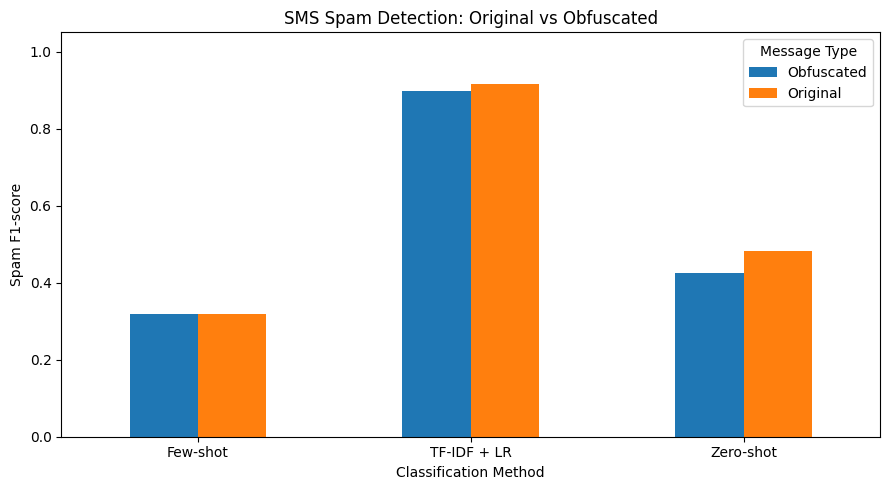


Confusion Matrix: TF-IDF + LR
Rows = Actual | Columns = Predicted


,ham,spam,invalid
ham,208,2,0
spam,3,27,0
invalid,0,0,0



Confusion Matrix: Zero-shot
Rows = Actual | Columns = Predicted


,ham,spam,invalid
ham,177,33,0
spam,10,20,0
invalid,0,0,0



Confusion Matrix: Few-shot
Rows = Actual | Columns = Predicted


,ham,spam,invalid
ham,82,128,0
spam,0,30,0
invalid,0,0,0


In [ ]:
# ==================================================
# CONSOLIDATE DEVELOPMENT METRICS
# ==================================================

metrics_dev = pd.concat(
    [e01_metrics, e02_metrics, e03_metrics],
    ignore_index=True
)

changed_dev = pd.concat(
    [e01_changed, e02_changed, e03_changed],
    ignore_index=True
)


# Combine predictions by matching message text
pred_dev = e01_predictions.merge(
    e02_predictions.drop(
        columns=["label", "obfuscated_text", "was_changed"]
    ),
    on="text",
    validate="one_to_one"
).merge(
    e03_predictions.drop(
        columns=["label", "obfuscated_text", "was_changed"]
    ),
    on="text",
    validate="one_to_one"
)


# Save development results
metrics_dev.to_csv(
    OUTPUT_DIR / "development_all_methods.csv",
    index=False
)

changed_dev.to_csv(
    OUTPUT_DIR / "development_changed_only.csv",
    index=False
)

pred_dev.to_csv(
    OUTPUT_DIR / "development_all_predictions.csv",
    index=False
)


print("ALL DEVELOPMENT RESULTS")

display(
    metrics_dev[
        [
            "experiment",
            "method",
            "scenario",
            "spam_precision",
            "spam_recall",
            "spam_f1"
        ]
    ].round(3)
)


# ==================================================
# DEVELOPMENT COMPARISON CHART
# ==================================================

order = [
    "Word TF-IDF + LR",
    "E01 Zero-shot",
    "E01 Few-shot",
    "E02 Zero-shot",
    "E02 Few-shot",
    "E03 FLAN-T5 Label Scoring",
    "E03 Character TF-IDF + LR"
]


plot_data = metrics_dev.pivot(
    index="method",
    columns="scenario",
    values="spam_f1"
).reindex(order)


ax = plot_data[
    ["Original", "Obfuscated"]
].plot(
    kind="bar",
    figsize=(13, 5),
    rot=30
)

ax.set_title(
    "Development: Spam F1 Across E01-E03"
)

ax.set_xlabel("Classification Method")
ax.set_ylabel("Spam F1-score")
ax.set_ylim(0, 1.05)

plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "development_f1_comparison.png",
    dpi=180
)

plt.show()


# ==================================================
# OBFUSCATION ERROR ANALYSIS
# ==================================================

error_rows = []

for method in order:

    safe = re.sub(
        r"[^a-zA-Z0-9]+",
        "_",
        method
    ).strip("_")

    p_orig = pred_dev[f"{safe}_Original"]
    p_obf = pred_dev[f"{safe}_Obfuscated"]

    disagreement = (
        dev_df.was_changed & p_orig.ne(p_obf)
    )

    for idx in np.flatnonzero(
        disagreement.to_numpy()
    ):

        error_rows.append({
            "method": method,
            "actual_label": dev_df.loc[idx, "label"],
            "original_text": dev_df.loc[idx, "text"],
            "obfuscated_text": dev_df.loc[idx, "obfuscated_text"],
            "original_prediction": p_orig.iloc[idx],
            "obfuscated_prediction": p_obf.iloc[idx]
        })


error_df = pd.DataFrame(
    error_rows,
    columns=[
        "method",
        "actual_label",
        "original_text",
        "obfuscated_text",
        "original_prediction",
        "obfuscated_prediction"
    ]
)


error_df.to_csv(
    OUTPUT_DIR / "obfuscation_prediction_changes.csv",
    index=False
)

print(
    "Predictions changed after obfuscation:",
    len(error_df)
)

display(error_df.head(8))

## 11. E04 — Modern SMS Evaluation

The original SMS Spam Collection is an older dataset.

Modern SMS messages include additional scenarios:

1. Personal conversations
2. Political campaign communications
3. Phishing and fraud
4. Commercial promotions

We created a small synthetic challenge set to investigate
how the models classify these message types.

### Political SMS

Political campaign messages can involve:

- Fundraising
- Event invitations
- Volunteer recruitment
- Campaign reminders

A political message is not automatically spam.

Whether it is unwanted can depend on user consent
and communication context.

### Evaluation Limitations

The 12 handcrafted messages have topic labels,
not independently verified spam/ham labels.

Therefore, this section provides qualitative analysis
rather than formal classification accuracy measurements.

In [ ]:
# ==================================================
# MODERN SMS CHALLENGE SET
# ==================================================

modern_sms = pd.DataFrame([
    (
        "personal",
        "Hey, can you pick up groceries tonight?"
    ),
    (
        "personal",
        "Your appointment is confirmed for Thursday."
    ),
    (
        "political",
        "Hello, this is the campaign volunteer team. "
        "Our town hall is next week."
    ),
    (
        "political",
        "Campaign update: Would you like to volunteer this weekend?"
    ),
    (
        "political",
        "Urgent campaign fundraising deadline tonight. "
        "Please consider donating."
    ),
    (
        "political",
        "Thank you for signing up for campaign event reminders."
    ),
    (
        "phishing",
        "Unpaid toll detected. Enter your payment details immediately."
    ),
    (
        "phishing",
        "Your bank account is locked. "
        "Verify your identity using this link."
    ),
    (
        "phishing",
        "We cannot process your donation. "
        "Reply with your credit card number."
    ),
    (
        "commercial",
        "Limited time! Get 50 percent off your next purchase."
    ),
    (
        "commercial",
        "Exclusive offer for new customers. Sign up today."
    ),
    (
        "commercial",
        "Congratulations! Claim your free gift card now."
    )
], columns=["topic", "text"])


# ==================================================
# APPLY ALL FIVE CLASSIFICATION METHODS
# ==================================================

MODERN_METHODS = [
    (
        "Word TF-IDF + LR",
        lambda x: predict_classical(x, word_model)
    ),
    (
        "E02 Zero-shot",
        lambda x: predict_generated(
            x, build_prompt_e02, "Zero-shot"
        )
    ),
    (
        "E02 Few-shot",
        lambda x: predict_generated(
            x, build_prompt_e02, "Few-shot"
        )
    ),
    (
        "E03 FLAN-T5 Label Scoring",
        predict_label_scoring
    ),
    (
        "E03 Character TF-IDF + LR",
        lambda x: predict_classical(x, char_model)
    )
]


for name, predictor in MODERN_METHODS:

    print("Classifying modern messages:", name)

    predictions, _, _ = predictor(
        modern_sms.text.tolist()
    )

    modern_sms[name] = predictions


# ==================================================
# SAVE RESULTS
# ==================================================

modern_sms.to_csv(
    OUTPUT_DIR / "e04_modern_sms_case_study.csv",
    index=False
)

display(modern_sms)

print(
    "Note: Topic labels are not verified binary spam labels."
)

SPAM MISSED AFTER OBFUSCATION
TF-IDF + LR | Newly missed spam: 1


,text,obfuscated_text
20,FREE GAME. Get Rayman Golf 4 FREE from the O2 ...,fr33 GAME. Get Rayman Golf 4 fr33 from the O2 ...


Zero-shot | Newly missed spam: 4


,text,obfuscated_text
21,We tried to contact you re our offer of New Vi...,We tried to contact you re our 0ffer of New Vi...
128,Free Msg: Ringtone!From: http://tms. widelive....,fr33 Msg: Ringtone!From: http://tms. widelive....
157,Congratulations U can claim 2 VIP row A Ticket...,Congratulations U can cl@im 2 VIP row A Ticket...


Few-shot | Newly missed spam: 0

ZERO-SHOT VS FEW-SHOT DISAGREEMENTS


,label,text,zero_shot,few_shot
1,ham,How do you guys go to see movies on your side.,ham,spam
3,ham,I want to tell you how bad I feel that basical...,ham,spam
4,spam,"cmon babe, make me horny, *turn* me on! Txt me...",ham,spam
5,ham,Dont flatter yourself... Tell that man of mine...,ham,spam
7,ham,Yunny i'm walking in citylink now Ã¼ faster co...,ham,spam
9,ham,Congrats. That's great. I wanted to tell you n...,ham,spam
13,ham,This is wishing you a great day. Moji told me ...,ham,spam
17,ham,Goodo! Yes we must speak friday - egg-potato r...,ham,spam


## 12. E05 — Final Unseen Evaluation

Our previous experiments evaluated the same 240 messages.

Repeatedly examining that development sample can influence
how we design the classification methods.

To evaluate generalization, E05 tests the finalized models
on a separate set of previously unseen messages.

### Evaluation Rules

- Do not retrain the classifiers using E05 messages.
- Do not modify prompts based on E05 results.
- Use the same model configurations from E02 and E03.
- Evaluate both original and obfuscated messages.

### Models

1. Word TF-IDF + Logistic Regression
2. FLAN-T5 Zero-shot (E02)
3. FLAN-T5 Few-shot (E02)
4. FLAN-T5 Candidate-Label Scoring (E03)
5. Character TF-IDF + Logistic Regression (E03)

The default final evaluation contains 300 messages.

The full remaining holdout pool contains 1,050 messages.

To evaluate the entire pool, set FINAL_SAMPLES = None
in the configuration cell before running this notebook.

E05 represents the independent final evaluation.

In [ ]:
# ==================================================
# E05 - FINAL HELD-OUT EVALUATION
# ==================================================

E05_METHODS = [
    (
        "E05",
        "Word TF-IDF + LR",
        lambda msgs: predict_classical(
            msgs, word_model
        )
    ),
    (
        "E05",
        "E02 Zero-shot",
        lambda msgs: predict_generated(
            msgs, build_prompt_e02, "Zero-shot"
        )
    ),
    (
        "E05",
        "E02 Few-shot",
        lambda msgs: predict_generated(
            msgs, build_prompt_e02, "Few-shot"
        )
    ),
    (
        "E05",
        "E03 FLAN-T5 Label Scoring",
        predict_label_scoring
    ),
    (
        "E05",
        "E03 Character TF-IDF + LR",
        lambda msgs: predict_classical(
            msgs, char_model
        )
    )
]


# Evaluate on the independent final dataset
e05_metrics, e05_changed, e05_predictions = (
    evaluate_methods(final_df, E05_METHODS)
)


# Save all results
save_experiment(
    "e05_final_holdout",
    e05_metrics,
    e05_changed,
    e05_predictions
)


print("\nFINAL UNSEEN EVALUATION RESULTS")

display(
    e05_metrics[
        [
            "method",
            "scenario",
            "n",
            "accuracy",
            "spam_precision",
            "spam_recall",
            "spam_f1"
        ]
    ].round(3)
)

SMS MESSAGE:
Congratulations! You have won a free cash prize. Claim it now!

CLASSIFICATION RESULTS
TF-IDF + Logistic Regression: spam
Zero-shot: 1/1
Zero-shot: spam
Raw model output: 'Spam'
Few-shot: 1/1
Few-shot: spam
Raw model output: 'spam'


## 13. Final Comparative Evaluation

We compare development-stage performance against
performance on unseen messages.

### Main Evaluation Metric

Spam F1-score is the primary metric because the
dataset contains substantially more ham than spam.

Additional metrics include:

- Accuracy
- Spam precision
- Spam recall
- False positives
- False negatives

### Visualizations

1. Development vs final evaluation F1-scores
2. Confusion matrices for the five classifiers
3. Final model ranking

The E05 evaluation is our primary evidence of
performance on unseen messages.

Development-stage results explain the evolution
of the project and the effects of each modification.

In [ ]:
# ==================================================
# COMPARE DEVELOPMENT AND FINAL EVALUATION
# ==================================================

main_order = [
    "Word TF-IDF + LR",
    "E02 Zero-shot",
    "E02 Few-shot",
    "E03 FLAN-T5 Label Scoring",
    "E03 Character TF-IDF + LR"
]


fig, axes = plt.subplots(
    1,
    2,
    figsize=(15, 5)
)


for ax, table, title in [
    (
        axes[0],
        metrics_dev,
        f"Development Sample (n={len(dev_df)})"
    ),
    (
        axes[1],
        e05_metrics,
        f"Final Unseen Sample (n={len(final_df)})"
    )
]:

    wide = table[
        table.method.isin(main_order)
    ].pivot(
        index="method",
        columns="scenario",
        values="spam_f1"
    ).reindex(main_order)

    wide[
        ["Original", "Obfuscated"]
    ].plot(
        kind="bar",
        ax=ax,
        rot=35
    )

    ax.set_title(title)
    ax.set_xlabel("")
    ax.set_ylabel("Spam F1-score")
    ax.set_ylim(0, 1.05)

    ax.legend(
        title="SMS Format",
        loc="upper right"
    )


plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "development_vs_final_f1.png",
    dpi=180
)

plt.show()


# ==================================================
# CONFUSION MATRICES FOR FINAL EVALUATION
# ==================================================

fig, axs = plt.subplots(
    2,
    3,
    figsize=(13, 8)
)

axs = axs.flatten()


for ax, method in zip(axs, main_order):

    safe = re.sub(
        r"[^a-zA-Z0-9]+",
        "_",
        method
    ).strip("_")

    pred = e05_predictions[
        f"{safe}_Original"
    ]

    label_names = [
        "ham",
        "spam",
        "invalid"
    ]

    cm = confusion_matrix(
        final_df.label,
        pred,
        labels=label_names
    )

    ax.imshow(
        cm,
        cmap="Blues"
    )

    for i in range(3):

        for j in range(3):

            ax.text(
                j,
                i,
                str(cm[i, j]),
                ha="center",
                va="center"
            )

    ax.set_xticks(
        range(3),
        labels=label_names
    )

    ax.set_yticks(
        range(3),
        labels=label_names
    )

    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")
    ax.set_title(method)


axs[-1].axis("off")

plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "e05_confusion_matrices.png",
    dpi=180
)

plt.show()


# ==================================================
# FINAL MODEL RANKING
# ==================================================

print("FINAL MODEL RANKING - ORIGINAL SMS")

display(
    e05_metrics[
        e05_metrics.scenario == "Original"
    ].sort_values(
        "spam_f1",
        ascending=False
    )[
        [
            "method",
            "accuracy",
            "spam_precision",
            "spam_recall",
            "spam_f1"
        ]
    ].round(3)
)

2209

## 14. Conclusion and Future Work

This project compares a traditional machine learning
classifier against two prompting strategies using
a pretrained language model.

The evaluation focuses on:

- Classification accuracy
- Spam precision and recall
- F1-score
- Computational runtime
- Robustness to keyword obfuscation

### Discussion Questions

1. Which method achieved the highest spam F1-score?
2. Did few-shot prompting improve results?
3. Which approach was most affected by obfuscation?
4. What types of messages caused classification errors?
5. How did inference times compare?

### Limitations

- Evaluation uses a historical SMS dataset.
- The LLM is not fine-tuned.
- Only one LLM checkpoint is evaluated.
- Few-shot performance may depend on example selection.
- Only a limited number of obfuscation patterns are tested.
- The public dataset may have been encountered during
  the pretrained model's development.

### Future Work

Potential extensions include:

- Evaluating additional LLMs
- Testing different numbers of few-shot examples
- Fine-tuning a language model
- Evaluating multilingual spam messages
- Testing additional adversarial text modifications

### References

1. Almeida, T. A., Hidalgo, J. M. G., & Yamakami, A.
   Contributions to the Study of SMS Spam Filtering:
   New Collection and Results. ACM DocEng, 2011.

2. UCI Machine Learning Repository.
   SMS Spam Collection.
   https://archive.ics.uci.edu/dataset/228/sms+spam+collection

3. Chung, H. W., et al.
   Scaling Instruction-Finetuned Language Models, 2022.
   https://arxiv.org/abs/2210.11416

4. Google FLAN-T5-base.
   https://huggingface.co/google/flan-t5-base

5. Pedregosa, F., et al.
   Scikit-learn: Machine Learning in Python.
   JMLR, 2011.

In [ ]:
import torch
import time
import pandas as pd

@torch.inference_mode()
def score_candidate_labels(messages, batch_size=12):

    messages = list(messages)
    candidates = ["ham", "spam"]

    target_ids = tokenizer(
        candidates,
        padding=True,
        return_tensors="pt"
    )["input_ids"].to(DEVICE)

    all_predictions = []
    started = time.perf_counter()

    for start in range(0, len(messages), batch_size):

        batch = messages[start:start + batch_size]

        prompts = [
            build_prompt(str(msg), "Zero-shot")
            for msg in batch
        ]

        inputs = tokenizer(
            prompts,
            padding=True,
            truncation=True,
            max_length=MAX_INPUT_TOKENS,
            return_tensors="pt"
        ).to(DEVICE)

        # Each message is paired with both candidate labels
        input_ids = inputs["input_ids"].repeat_interleave(2, dim=0)
        attention_mask = inputs["attention_mask"].repeat_interleave(2, dim=0)

        labels = target_ids.repeat(len(batch), 1)
        labels[labels == tokenizer.pad_token_id] = -100

        # Teacher-forced candidate scoring
        outputs = model(
            input_ids=input_ids,
            attention_mask=attention_mask,
            labels=labels
        )

        log_probs = torch.log_softmax(
            outputs.logits.float(),
            dim=-1
        )

        valid = labels != -100

        token_scores = log_probs.gather(
            -1,
            labels.clamp(min=0).unsqueeze(-1)
        ).squeeze(-1)

        token_scores = token_scores.masked_fill(
            ~valid, 0
        )

        scores = token_scores.sum(dim=1).reshape(
            len(batch), 2
        )

        best_indices = scores.argmax(dim=1).tolist()

        all_predictions.extend(
            candidates[i] for i in best_indices
        )

    elapsed = time.perf_counter() - started

    return all_predictions, elapsed


# Evaluate original and obfuscated messages
e03_predictions = {}

for scenario, column in [
    ("Original", "text"),
    ("Obfuscated", "obfuscated_text")
]:
    pred, elapsed = score_candidate_labels(
        eval_df[column]
    )

    e03_predictions[scenario] = pred

    print(f"\nE03 - {scenario}")
    print(f"Inference time: {elapsed:.2f} seconds")

    print(classification_report(
        eval_df["label"],
        pred,
        labels=["ham", "spam"],
        zero_division=0
    ))

    print("Predicted class distribution:")
    print(pd.Series(pred).value_counts())


E03 - Original
Inference time: 224.49 seconds
              precision    recall  f1-score   support

         ham       0.95      0.99      0.97       210
        spam       0.86      0.63      0.73        30

    accuracy                           0.94       240
   macro avg       0.91      0.81      0.85       240
weighted avg       0.94      0.94      0.94       240

Predicted class distribution:
ham     218
spam     22
Name: count, dtype: int64

E03 - Obfuscated
Inference time: 226.96 seconds
              precision    recall  f1-score   support

         ham       0.94      0.99      0.96       210
        spam       0.85      0.57      0.68        30

    accuracy                           0.93       240
   macro avg       0.90      0.78      0.82       240
weighted avg       0.93      0.93      0.93       240

Predicted class distribution:
ham     220
spam     20
Name: count, dtype: int64


In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, f1_score

char_model = Pipeline([
    ("tfidf", TfidfVectorizer(
        analyzer="char",
        ngram_range=(3, 5),
        min_df=2,
        max_features=60000,
        sublinear_tf=True
    )),
    ("classifier", LogisticRegression(
        max_iter=1500,
        class_weight="balanced",
        random_state=SEED
    ))
])

# Same training data as E01/E02
char_model.fit(
    train_df["text"],
    train_df["label"]
)

# Same evaluation data
for scenario, column in [
    ("Original", "text"),
    ("Obfuscated", "obfuscated_text")
]:
    predictions_char = char_model.predict(
        eval_df[column]
    )

    print(f"\nCharacter TF-IDF - {scenario}")

    print(classification_report(
        eval_df["label"],
        predictions_char,
        labels=["ham", "spam"],
        zero_division=0
    ))

    print("Spam F1:", round(
        f1_score(
            eval_df["label"],
            predictions_char,
            pos_label="spam"
        ), 4
    ))


Character TF-IDF - Original
              precision    recall  f1-score   support

         ham       0.99      1.00      0.99       210
        spam       1.00      0.90      0.95        30

    accuracy                           0.99       240
   macro avg       0.99      0.95      0.97       240
weighted avg       0.99      0.99      0.99       240

Spam F1: 0.9474

Character TF-IDF - Obfuscated
              precision    recall  f1-score   support

         ham       0.99      1.00      0.99       210
        spam       1.00      0.90      0.95        30

    accuracy                           0.99       240
   macro avg       0.99      0.95      0.97       240
weighted avg       0.99      0.99      0.99       240

Spam F1: 0.9474


In [ ]:
modern_sms = pd.DataFrame([
    ("personal", "Hey, can you pick up groceries tonight?"),
    ("personal", "Your appointment is confirmed for Thursday."),

    ("political", "Hello, this is the campaign volunteer team. Our town hall is next week."),
    ("political", "Campaign update: Would you like to volunteer this weekend?"),
    ("political", "Urgent campaign fundraising deadline tonight. Please consider donating."),
    ("political", "Thank you for signing up for campaign event reminders."),

    ("phishing", "Unpaid toll detected. Enter your payment details immediately."),
    ("phishing", "Your bank account is locked. Verify your identity using this link."),
    ("phishing", "We cannot process your donation. Reply with your credit card number."),

    ("commercial", "Limited time! Get 50 percent off your next purchase."),
    ("commercial", "Exclusive offer for new customers. Sign up today."),
    ("commercial", "Congratulations! Claim your free gift card now.")
], columns=["topic", "text"])

# Run existing models
modern_sms["traditional_ml"] = baseline.predict(
    modern_sms["text"]
)

modern_sms["zero_shot"], _, _ = flan_predict(
    modern_sms["text"],
    "Zero-shot"
)

modern_sms["few_shot"], _, _ = flan_predict(
    modern_sms["text"],
    "Few-shot"
)

modern_sms["candidate_scoring"], _ = score_candidate_labels(
    modern_sms["text"]
)

display(modern_sms)

modern_sms.to_csv(
    OUTPUT_DIR / "modern_sms_case_study.csv",
    index=False
)

Zero-shot: 12/12
Few-shot: 12/12


,topic,text,traditional_ml,zero_shot,few_shot,candidate_scoring
0,personal,"Hey, can you pick up groceries tonight?",ham,ham,ham,ham
1,personal,Your appointment is confirmed for Thursday.,ham,ham,ham,ham
2,political,"Hello, this is the campaign volunteer team. Ou...",spam,ham,spam,ham
3,political,Campaign update: Would you like to volunteer t...,ham,spam,spam,ham
4,political,Urgent campaign fundraising deadline tonight. ...,ham,spam,spam,spam
5,political,Thank you for signing up for campaign event re...,ham,spam,spam,ham
6,phishing,Unpaid toll detected. Enter your payment detai...,ham,spam,spam,ham
7,phishing,Your bank account is locked. Verify your ident...,spam,spam,spam,ham
8,phishing,We cannot process your donation. Reply with yo...,spam,spam,spam,spam
9,commercial,Limited time! Get 50 percent off your next pur...,spam,spam,spam,ham


All required experiment variables found.

===== COMPLETE MODEL COMPARISON =====


,method,scenario,accuracy,spam_precision,spam_recall,spam_f1,inference_seconds
0,Few-shot,Obfuscated,0.462,0.189,1.000,0.317,194.37
1,Few-shot,Original,0.467,0.190,1.000,0.319,194.74
2,TF-IDF + LR,Obfuscated,0.975,0.929,0.867,0.897,0.01
3,TF-IDF + LR,Original,0.979,0.931,0.900,0.915,0.02
4,Zero-shot,Obfuscated,0.808,0.340,0.567,0.425,127.00
5,Zero-shot,Original,0.821,0.377,0.667,0.482,166.43
6,FLAN-T5 Label Scoring,Original,0.942,0.864,0.633,0.731,NaN
7,Character TF-IDF + LR,Original,0.988,1.000,0.900,0.947,0.08
8,FLAN-T5 Label Scoring,Obfuscated,0.933,0.850,0.567,0.680,NaN
9,Character TF-IDF + LR,Obfuscated,0.988,1.000,0.900,0.947,0.08


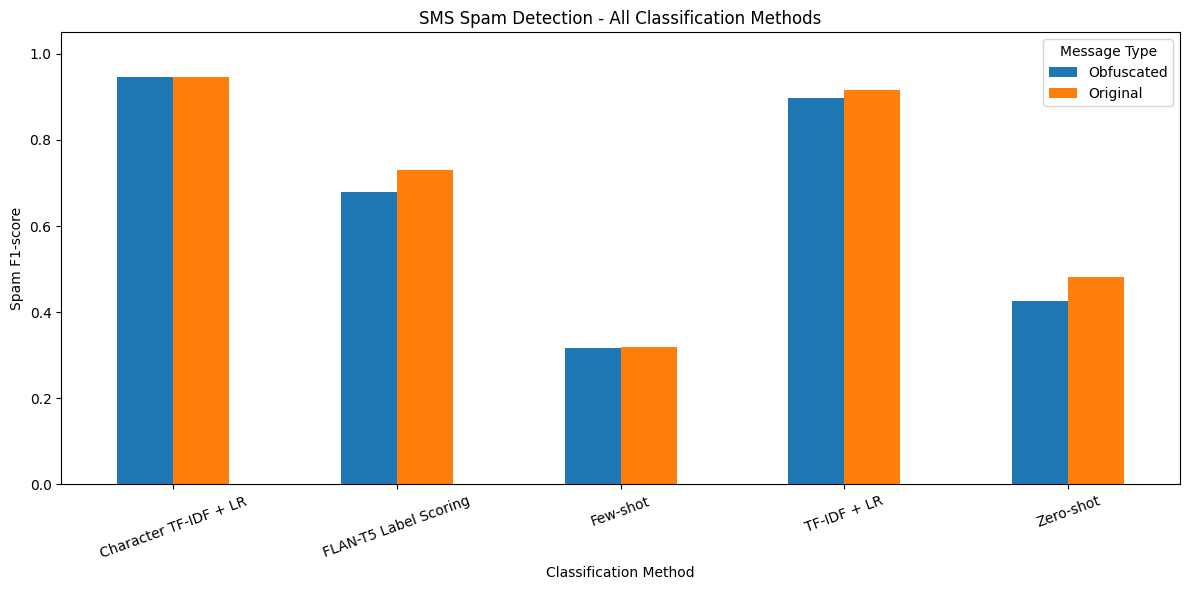


===== MODERN SMS EVALUATION =====


,topic,text,traditional_ml,zero_shot,few_shot,candidate_scoring
0,personal,"Hey, can you pick up groceries tonight?",ham,ham,ham,ham
1,personal,Your appointment is confirmed for Thursday.,ham,ham,ham,ham
2,political,"Hello, this is the campaign volunteer team. Ou...",spam,ham,spam,ham
3,political,Campaign update: Would you like to volunteer t...,ham,spam,spam,ham
4,political,Urgent campaign fundraising deadline tonight. ...,ham,spam,spam,spam
5,political,Thank you for signing up for campaign event re...,ham,spam,spam,ham
6,phishing,Unpaid toll detected. Enter your payment detai...,ham,spam,spam,ham
7,phishing,Your bank account is locked. Verify your ident...,spam,spam,spam,ham
8,phishing,We cannot process your donation. Reply with yo...,spam,spam,spam,spam
9,commercial,Limited time! Get 50 percent off your next pur...,spam,spam,spam,ham



===== SAVED RESULTS =====
- comparison_all_methods.png
- message_predictions.csv
- metrics.csv
- metrics_all_methods.csv
- metrics_changed_only.csv
- metrics_e03.csv
- metrics_e03_changed_only.csv
- modern_sms_case_study.csv
- predictions_e03.csv
- result_summary.txt
- spam_f1_comparison.png

All results successfully consolidated!
ZIP file: /content/SMS_Spam_Project_Complete_Results.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# ============================================================
# FINAL RESULTS - E02, E03, E04
# Consolidate all experiments and download ONE ZIP
# ============================================================

import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from shutil import make_archive
from google.colab import files

OUTPUT_DIR = Path("project_results")
OUTPUT_DIR.mkdir(exist_ok=True)

# ------------------------------------------------------------
# 1. Verify required experiments have completed
# ------------------------------------------------------------

assert "Original" in e03_predictions
assert "Obfuscated" in e03_predictions

assert "char_model" in globals()
assert "results" in globals()
assert "modern_sms" in globals()

print("All required experiment variables found.")

# ------------------------------------------------------------
# 2. Calculate E03 metrics
# ------------------------------------------------------------

new_metrics = []
new_changed_metrics = []

truth = eval_df["label"].tolist()

changed_idx = np.flatnonzero(
    eval_df["was_changed"].to_numpy()
)

e03_details = eval_df[
    ["label", "text", "obfuscated_text", "was_changed"]
].copy()

for scenario, column in [
    ("Original", "text"),
    ("Obfuscated", "obfuscated_text")
]:

    # FLAN-T5 candidate-label scoring
    scoring_pred = list(e03_predictions[scenario])

    # Character-level TF-IDF + Logistic Regression
    start = time.perf_counter()

    char_pred = char_model.predict(
        eval_df[column]
    ).tolist()

    char_seconds = time.perf_counter() - start

    for method, pred, seconds in [
        ("FLAN-T5 Label Scoring", scoring_pred, np.nan),
        ("Character TF-IDF + LR", char_pred, char_seconds)
    ]:

        assert len(pred) == len(truth)

        # Metrics on all evaluation messages
        new_metrics.append(
            calculate_metrics(
                truth,
                pred,
                method,
                scenario,
                len(changed_idx),
                seconds
            )
        )

        # Metrics on modified messages only
        changed_truth = [
            truth[i] for i in changed_idx
        ]

        changed_pred = [
            pred[i] for i in changed_idx
        ]

        new_changed_metrics.append(
            calculate_metrics(
                changed_truth,
                changed_pred,
                method,
                scenario,
                len(changed_idx),
                np.nan
            )
        )

        # Store individual predictions
        col_name = (
            method.replace(" ", "_").replace("-", "_")
            + "_" + scenario
        )

        e03_details[col_name] = pred

# ------------------------------------------------------------
# 3. Combine E02 and E03 results
# ------------------------------------------------------------

e03_metrics = pd.DataFrame(new_metrics)
e03_changed = pd.DataFrame(new_changed_metrics)

all_metrics = pd.concat(
    [results, e03_metrics],
    ignore_index=True
)

# Export metrics
all_metrics.to_csv(
    OUTPUT_DIR / "metrics_all_methods.csv",
    index=False
)

e03_metrics.to_csv(
    OUTPUT_DIR / "metrics_e03.csv",
    index=False
)

e03_changed.to_csv(
    OUTPUT_DIR / "metrics_e03_changed_only.csv",
    index=False
)

e03_details.to_csv(
    OUTPUT_DIR / "predictions_e03.csv",
    index=False
)

print("\n===== COMPLETE MODEL COMPARISON =====")

display(
    all_metrics[
        [
            "method",
            "scenario",
            "accuracy",
            "spam_precision",
            "spam_recall",
            "spam_f1",
            "inference_seconds"
        ]
    ].round(3)
)

# ------------------------------------------------------------
# 4. Generate updated comparison chart
# ------------------------------------------------------------

plot_data = all_metrics.pivot(
    index="method",
    columns="scenario",
    values="spam_f1"
)

ax = plot_data.plot(
    kind="bar",
    figsize=(12, 6),
    rot=20
)

ax.set_title(
    "SMS Spam Detection - All Classification Methods"
)

ax.set_ylabel("Spam F1-score")
ax.set_xlabel("Classification Method")
ax.set_ylim(0, 1.05)
ax.legend(title="Message Type")

plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "comparison_all_methods.png",
    dpi=180
)

plt.show()

# ------------------------------------------------------------
# 5. Save E04 modern SMS evaluation
# ------------------------------------------------------------

modern_sms.to_csv(
    OUTPUT_DIR / "modern_sms_case_study.csv",
    index=False
)

print("\n===== MODERN SMS EVALUATION =====")

display(modern_sms)

# ------------------------------------------------------------
# 6. Export all results into ONE ZIP file
# ------------------------------------------------------------

print("\n===== SAVED RESULTS =====")

for file in sorted(OUTPUT_DIR.iterdir()):
    if file.is_file():
        print("-", file.name)

archive_path = make_archive(
    "SMS_Spam_Project_Complete_Results",
    "zip",
    root_dir=".",
    base_dir=str(OUTPUT_DIR)
)

print("\nAll results successfully consolidated!")
print("ZIP file:", archive_path)

# Download only once
files.download(archive_path)